# Processamento da matriz de scRNA-seq de HepG2

Este notebook prepara a matriz de expressão que alimenta a inferência das redes: a matriz de
contagens é lida, convertida para o formato loom, filtrada por qualidade e gravada no formato
que o pySCENIC consome.

É uma adaptação do notebook `PBMC10k_SCENIC-protocol-CLI.ipynb`, do repositório
[aertslab/SCENICprotocol](https://github.com/aertslab/SCENICprotocol), que acompanha o protocolo
publicado em Van de Sande et al., Nature Protocols, 2020 (doi 10.1038/s41596-020-0336-2) e está
sob licença GPL-3.0. As etapas de diagnóstico e de filtragem básica vêm de lá, onde são aplicadas
a um conjunto de PBMCs. O que muda aqui é a matriz de entrada e o corte por número de genes, que
é calculado a partir da distribuição da própria amostra.

| Seção | Etapa |
|---|---|
| 0 | Configuração e caminhos |
| 1 | Leitura da matriz de expressão |
| 2 | Conversão para loom |
| 3 | Diagnóstico antes da filtragem |
| 4 | Filtragem |
| 5 | Diagnóstico depois da filtragem |
| 6 | Arquivos de saída |

Os caminhos são relativos ao diretório de trabalho, que precisa ser a raiz do projeto.

# 0. Configuração

## 0.1. Imports

In [1]:
from pathlib import Path

import loompy as lp
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc
import seaborn as sns
from scipy.sparse import issparse

/home/linux/miniconda3/envs/pyscenic_inf/lib/python3.8/site-packages/loompy/bus_file.py:68: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def twobit_to_dna(twobit: int, size: int) -> str:
/home/linux/miniconda3/envs/pyscenic_inf/lib/python3.8/site-packages/loompy/bus_file.py:85: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  def dna_to_twobit(dna: str) -> int:
/h

## 0.2. Caminhos

Entradas e saídas do notebook. As pastas `data/` e `outs/` são criadas se ainda não existirem.

In [2]:
DATA = Path("data")
OUTS = Path("outs")
DATA.mkdir(parents=True, exist_ok=True)
OUTS.mkdir(parents=True, exist_ok=True)

# Matriz de contagens da amostra, genes nas linhas e células nas colunas
MATRIZ = DATA / "scCite_HepG2_RNA.txt"

# Loom com a matriz inteira, antes de qualquer corte
LOOM_NAO_FILTRADO = DATA / "Hepg2_GSM5677000_unfiltered.loom"

# Saídas: objeto do scanpy e loom filtrado, que é o que entra no pySCENIC
ANNDATA = DATA / "anndata.h5ad"
LOOM_FILTRADO = DATA / "Hepg2_GSM5677000_filtered_scenic.loom"

# Painéis de diagnóstico
FIG_PRE_FILTRO = OUTS / "filtering_panel_prefilter.pdf"
FIG_POS_FILTRO = OUTS / "filtering_panel_postfilter.pdf"

## 0.3. Ajustes do scanpy

`print_header` registra as versões das bibliotecas na saída da célula, o que ajuda a distinguir
mudança de dado de mudança de versão quando um resultado não se repete.

In [3]:
sc.settings.verbosity = 3        # 0 erros, 1 avisos, 2 informação, 3 dicas
sc.settings.njobs = 8
sc.set_figure_params(dpi=150, fontsize=10, dpi_save=600)
sc.logging.print_header()

/home/linux/miniconda3/envs/pyscenic_inf/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


scanpy==1.7.2 anndata==0.7.8 umap==0.5.6 numpy==1.23.5 scipy==1.10.1 pandas==1.3.5 scikit-learn==1.1.2 statsmodels==0.13.2 python-igraph==0.9.9 louvain==0.7.0


# 1. Leitura da matriz de expressão

A matriz usada é a da amostra de HepG2 do GEO cujo download está no notebook
`aquisicao_dados.ipynb`. Este notebook espera o arquivo já descompactado em
`data/scCite_HepG2_RNA.txt`, em texto separado por tabulação, com os genes nas linhas, as células
nas colunas e os nomes dos genes na primeira coluna, daí o `first_column_names=True`.

Com essa orientação, o scanpy lê os genes como observações e as células como variáveis, o que se
inverte na Seção 3, quando a matriz volta do arquivo loom. Se a matriz vier no formato 10x, com
os arquivos `barcodes`, `features` e `matrix.mtx` numa pasta, a leitura equivalente é
`sc.read_10x_mtx`, e nesse caso as células já entram como observações.

In [4]:
adata = sc.read_text(MATRIZ, delimiter="\t", first_column_names=True)

print(f"{adata.n_obs} genes x {adata.n_vars} células")

34866 genes x 1628 células


# 2. Conversão para loom

O pySCENIC lê a matriz em formato loom, com os genes nas linhas e as células nas colunas. Junto
da matriz vão dois atributos por célula, `nGene`, o número de genes detectados, e `nUMI`, o total
de contagens.

Este é o loom da matriz inteira, sem nenhum corte. O loom filtrado, que entra de fato na
inferência, é gravado na Seção 6.

In [5]:
X = adata.X   # genes nas linhas, células nas colunas

if issparse(X):
    n_genes_por_celula = X.getnnz(axis=0)
    n_umi_por_celula = np.asarray(X.sum(axis=0)).ravel()
else:
    n_genes_por_celula = np.asarray((X > 0).sum(axis=0)).ravel()
    n_umi_por_celula = np.asarray(X.sum(axis=0)).ravel()

row_attrs = {"Gene": np.array(adata.obs_names)}
col_attrs = {
    "CellID": np.array(adata.var_names),
    "nGene": np.array(n_genes_por_celula).ravel(),
    "nUMI": np.array(n_umi_por_celula).ravel(),
}

lp.create(str(LOOM_NAO_FILTRADO), X, row_attrs, col_attrs)

print(f"{LOOM_NAO_FILTRADO}: {X.shape[0]} genes x {X.shape[1]} células")

data/Hepg2_GSM5677000_unfiltered.loom: 34866 genes x 1628 células


# 3. Diagnóstico antes da filtragem

A matriz volta do loom com as células nas linhas e os genes nas colunas, que é a orientação usada
pelo scanpy daqui em diante.

Três medidas por célula guiam a filtragem: o número de genes detectados (`n_genes`), o total de
contagens (`n_counts`) e a fração de leituras em genes mitocondriais (`percent_mito`), que são os
genes com prefixo `MT-`. Fração mitocondrial alta é indício de célula danificada ou em morte, e
número de genes muito acima do restante da amostra é indício de dupleto.

In [6]:
adata = sc.read_loom(LOOM_NAO_FILTRADO)

print(f"{adata.n_obs} células x {adata.n_vars} genes")

1628 células x 34866 genes


Duas medidas por gene, antes das medidas por célula. Junto delas saem os limiares de referência
do pySCENIC, três contagens em 1% das células e detecção em 1% das células, que aqui servem de
comparação com os cortes da Seção 4 e não são aplicados.

In [7]:
contagens_por_gene = np.sum(adata.X, axis=0)
celulas_por_gene = np.sum(adata.X > 0, axis=0)

print(f"Contagens por gene: {contagens_por_gene.min()} a {contagens_por_gene.max()}")
print(f"Células em que o gene é detectado: {celulas_por_gene.min()} a {celulas_por_gene.max()}")

n_celulas = adata.n_obs
print(f"Referência do pySCENIC: {3 * 0.01 * n_celulas:.2f} contagens por gene "
      f"(3 contagens em 1% das células) e {0.01 * n_celulas:.2f} células por gene")

Contagens por gene: 0.0 a 2261874.0
Células em que o gene é detectado: 0 a 1628
Referência do pySCENIC: 48.84 contagens por gene (3 contagens em 1% das células) e 16.28 células por gene


In [8]:
sc.pp.filter_cells(adata, min_genes=0)   # cria a coluna n_genes

mitocondriais = adata.var_names.str.startswith("MT-")
contagens_mito = np.asarray(adata[:, mitocondriais].X.sum(axis=1)).ravel()
contagens_totais = np.asarray(adata.X.sum(axis=1)).ravel()

adata.obs["percent_mito"] = contagens_mito / contagens_totais
adata.obs["n_counts"] = contagens_totais

adata.obs.head()

,nGene,nUMI,n_genes,percent_mito,n_counts
CellID,,,,,
HepG2_TGACGGCCGGTACTAATGGC.HepG2,10728,131781.0,10728,0.046046,131781.0
HepG2_CGTCGTTCAGTATCATCTCT.HepG2,10816,150311.0,10816,0.045539,150311.0
HepG2_ATATTAGAGCGTAGACGGAG.HepG2,10116,139503.0,10116,0.084615,139503.0
HepG2_TACAAGCACCTTCTCACTCC.HepG2,11136,129413.0,11136,0.058016,129413.0
HepG2_CTCAAGGACACTGATACTTC.HepG2,10012,136447.0,10012,0.014035,136447.0


## 3.1. Genes detectados por célula

O mesmo histograma três vezes: inteiro, com a cauda de baixo ampliada e com a cauda de cima
ampliada. São as duas caudas que o corte da Seção 4 remove.

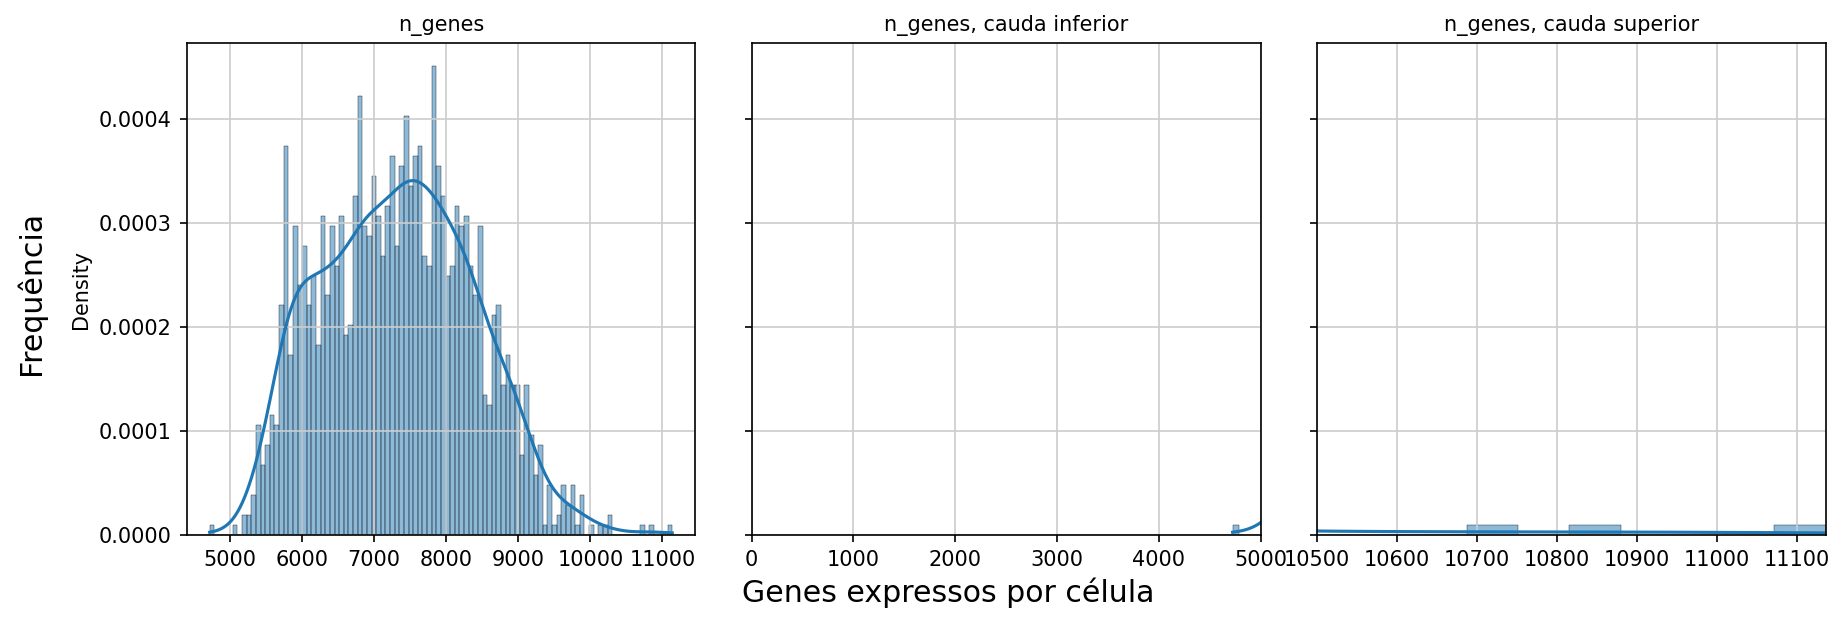

In [9]:
ZOOM_CAUDA_INFERIOR = 5000
ZOOM_CAUDA_SUPERIOR = 10500

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

for ax in (ax1, ax2, ax3):
    sns.histplot(adata.obs["n_genes"], ax=ax, stat="density", bins=100, kde=True)
    ax.set_xlabel("")

ax2.set_xlim(0, ZOOM_CAUDA_INFERIOR)
ax3.set_xlim(ZOOM_CAUDA_SUPERIOR, adata.obs["n_genes"].max())

ax1.set_title("n_genes")
ax2.set_title("n_genes, cauda inferior")
ax3.set_title("n_genes, cauda superior")

fig.text(-0.01, 0.5, "Frequência", ha="center", va="center", rotation="vertical", size="x-large")
fig.text(0.5, 0.0, "Genes expressos por célula", ha="center", va="center", size="x-large")

fig.tight_layout()

## 3.2. Fração mitocondrial por célula

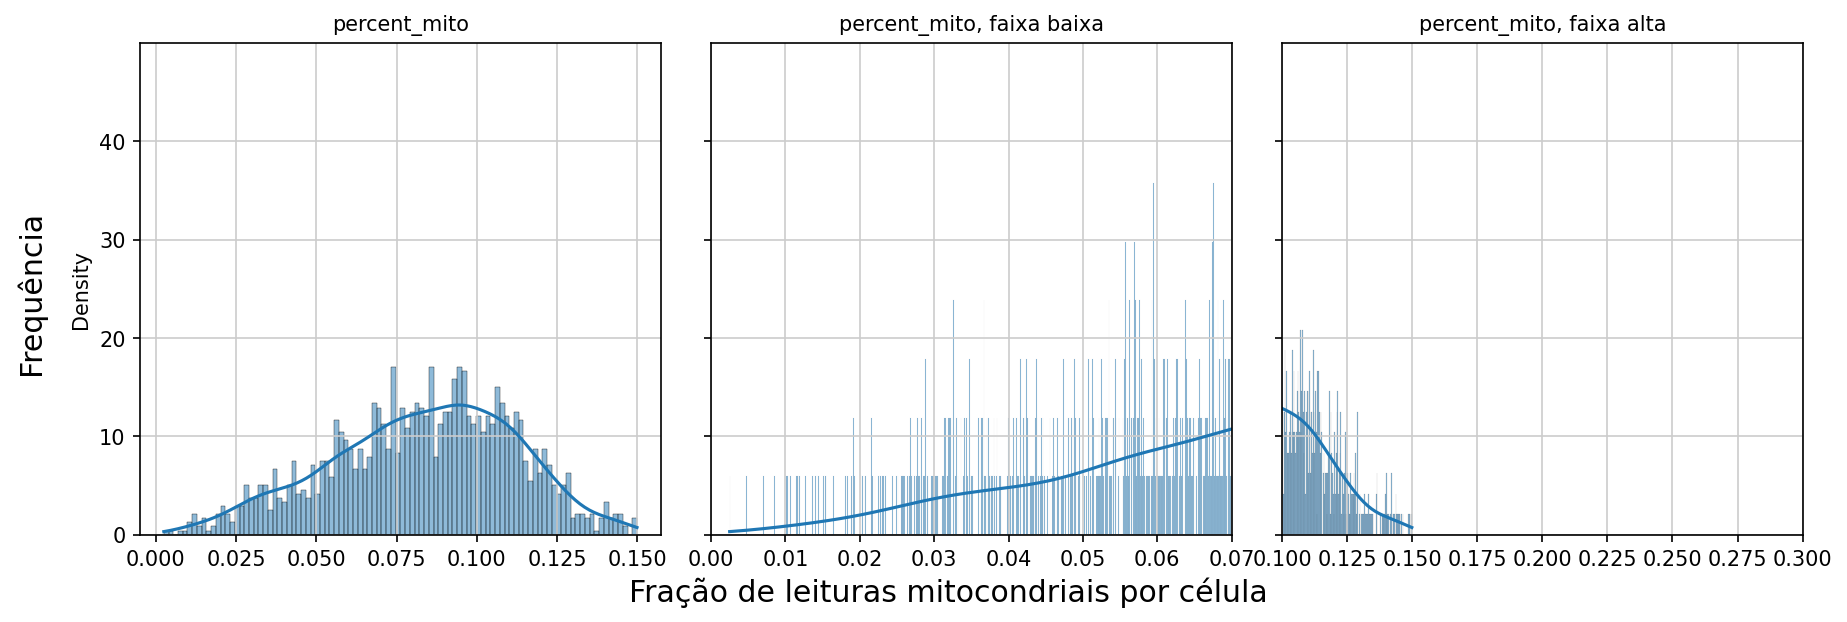

In [10]:
FAIXA_INFERIOR = (0.0, 0.07)
FAIXA_SUPERIOR = (0.10, 0.30)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=True)

sns.histplot(adata.obs["percent_mito"], ax=ax1, stat="density", bins=100, kde=True)
sns.histplot(adata.obs["percent_mito"], ax=ax2, stat="density", kde=True,
             bins=int(100 / (FAIXA_INFERIOR[1] - FAIXA_INFERIOR[0])))
sns.histplot(adata.obs["percent_mito"], ax=ax3, stat="density", kde=True,
             bins=int(100 / (FAIXA_SUPERIOR[1] - FAIXA_SUPERIOR[0])))

ax2.set_xlim(*FAIXA_INFERIOR)
ax3.set_xlim(*FAIXA_SUPERIOR)
for ax in (ax1, ax2, ax3):
    ax.set_xlabel("")

ax1.set_title("percent_mito")
ax2.set_title("percent_mito, faixa baixa")
ax3.set_title("percent_mito, faixa alta")

fig.text(-0.01, 0.5, "Frequência", ha="center", va="center", rotation="vertical", size="x-large")
fig.text(0.5, 0.0, "Fração de leituras mitocondriais por célula", ha="center", va="center",
         size="x-large")

fig.tight_layout()

## 3.3. Painel das três medidas

O painel é gravado em `outs/filtering_panel_prefilter.pdf` e repetido na Seção 5, depois da
filtragem, para comparação.

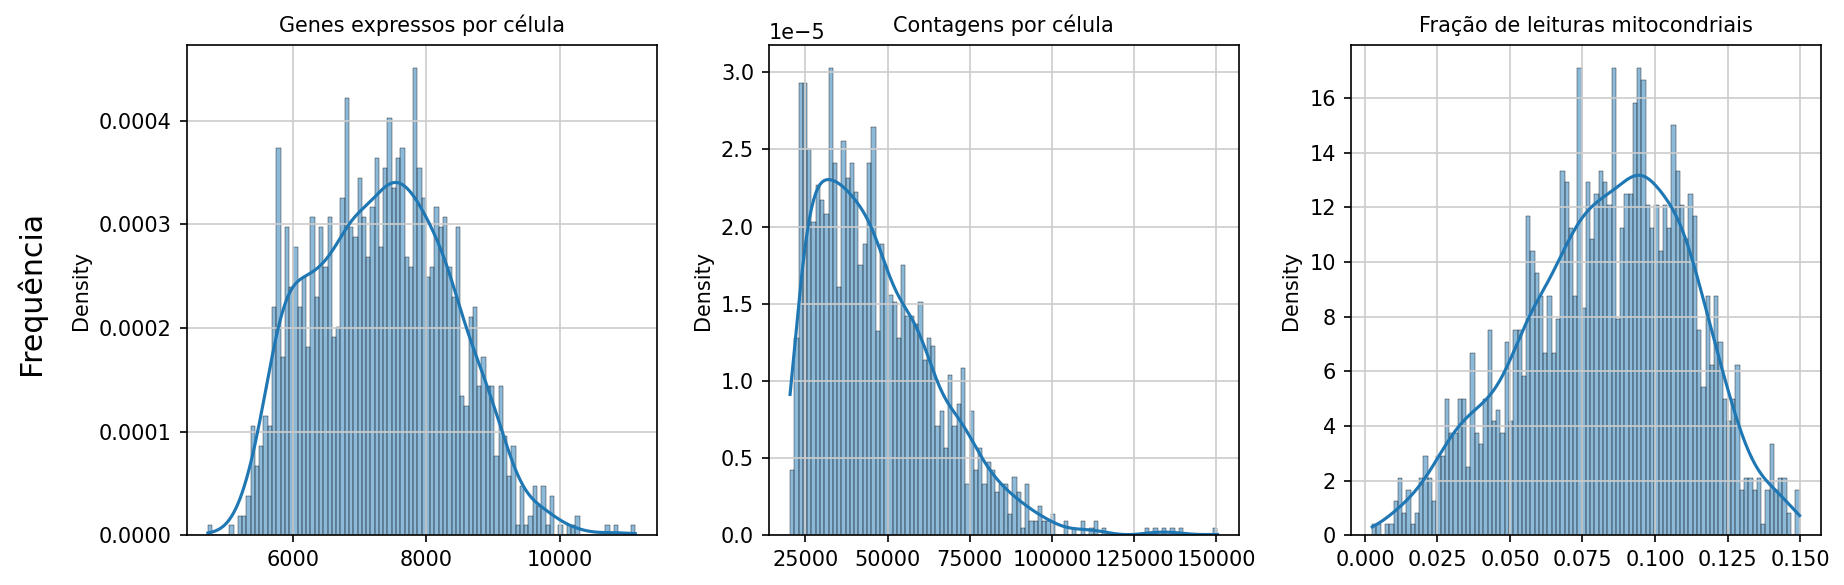

In [11]:
def painel_diagnostico(adata, caminho_pdf):
    fig, eixos = plt.subplots(1, 3, figsize=(12, 4), dpi=150, sharey=False)
    medidas = [("n_genes", "Genes expressos por célula"),
               ("n_counts", "Contagens por célula"),
               ("percent_mito", "Fração de leituras mitocondriais")]

    for ax, (coluna, titulo) in zip(eixos, medidas):
        sns.histplot(adata.obs[coluna], ax=ax, stat="density", bins=100, kde=True)
        ax.set_title(titulo)
        ax.set_xlabel("")

    fig.text(-0.01, 0.5, "Frequência", ha="center", va="center", rotation="vertical",
             size="x-large")
    fig.tight_layout()
    fig.savefig(caminho_pdf, dpi=600, bbox_inches="tight")


painel_diagnostico(adata, FIG_PRE_FILTRO)

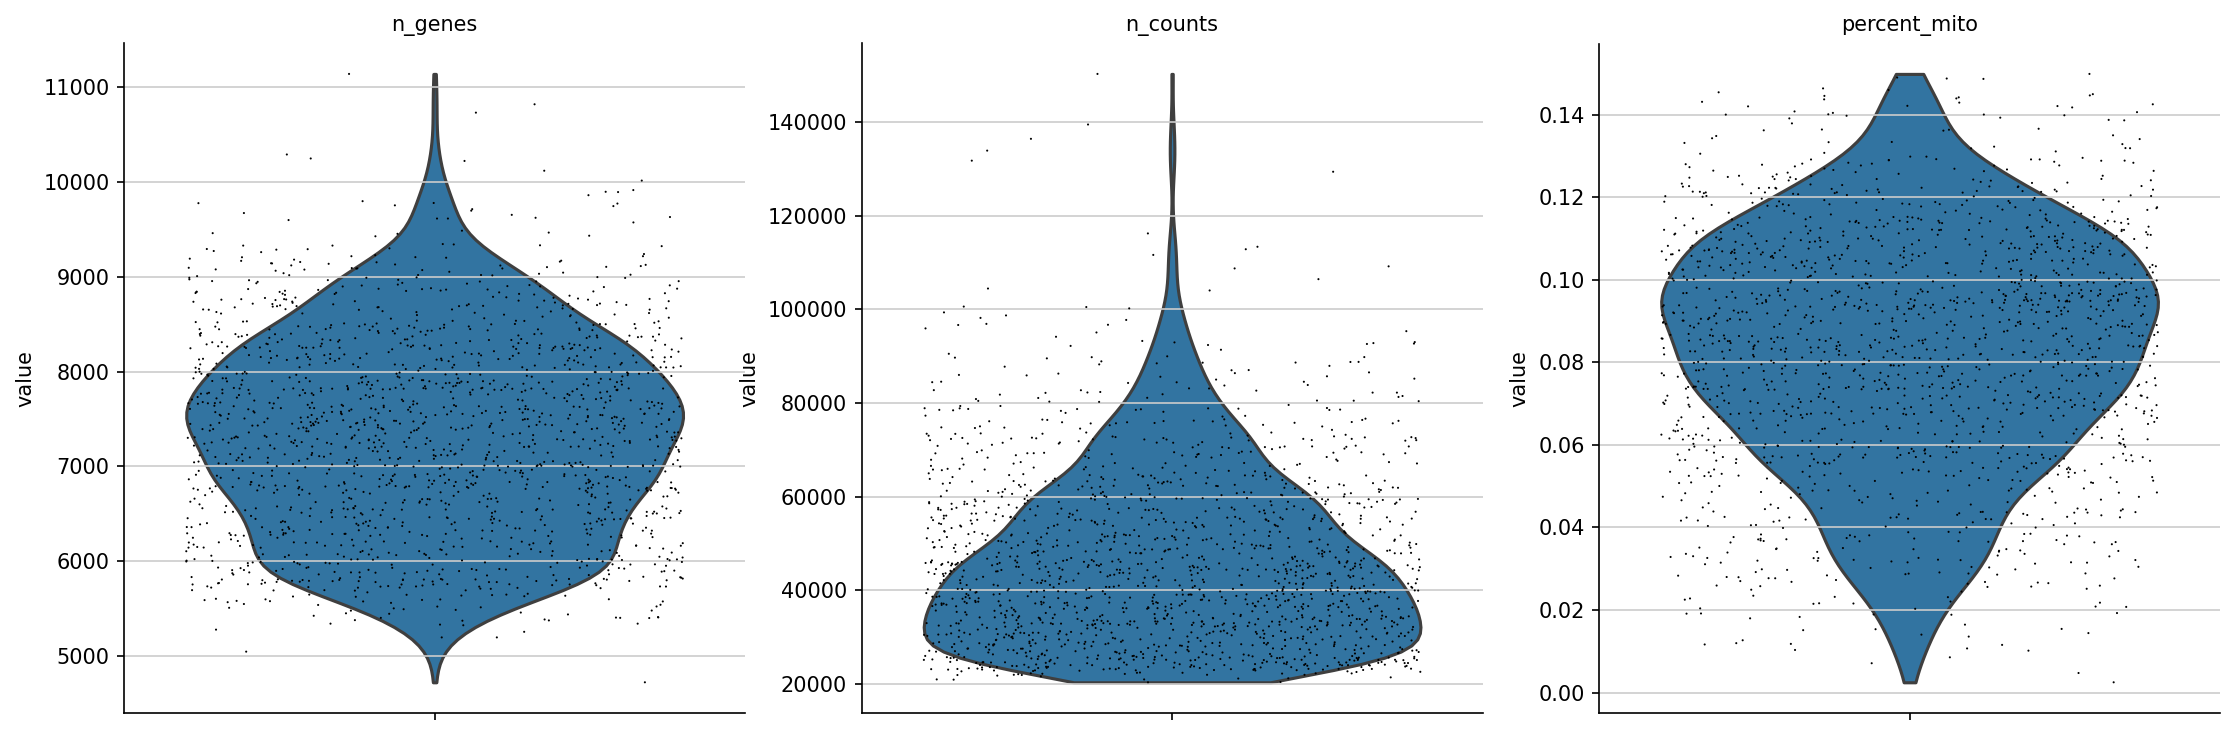

In [12]:
sc.pl.violin(adata, ["n_genes", "n_counts", "percent_mito"], jitter=0.4, multi_panel=True)

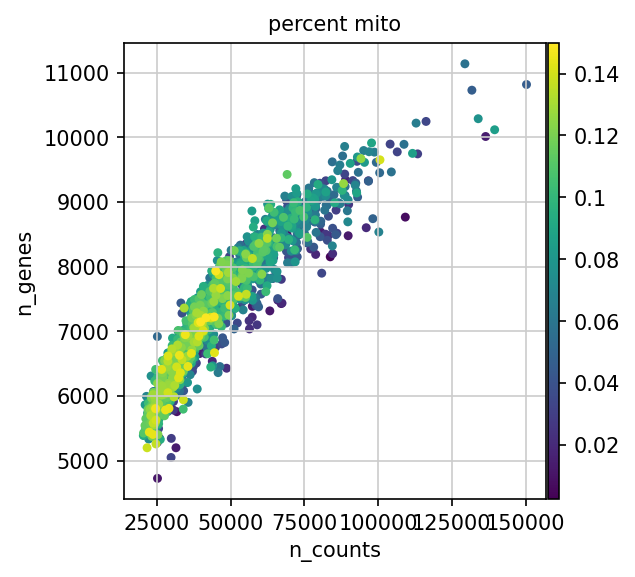

In [13]:
sc.pl.scatter(adata, x="n_counts", y="n_genes", color="percent_mito")

# 4. Filtragem

Primeiro os dois cortes do protocolo: sai a célula com menos de 200 genes detectados e sai o gene
detectado em menos de três células.

Depois saem as células extremas em número de genes, por um critério calculado na própria amostra.
A regra do IQR trata como extremo o que estiver a mais de 1,5 intervalo interquartil abaixo do
primeiro quartil ou acima do terceiro. A célula seguinte imprime esses limites, e os valores
aplicados estão escritos na célula do corte, de modo que a filtragem não mude sozinha se a matriz
for substituída. O terceiro critério é a fração mitocondrial, com o corte de 15% do protocolo.

In [14]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

filtered out 9826 genes that are detected in less than 3 cells


In [15]:
def limites_iqr(valores, multiplicador=1.5):
    q1, q3 = valores.quantile(0.25), valores.quantile(0.75)
    amplitude = q3 - q1
    return max(0, q1 - multiplicador * amplitude), q3 + multiplicador * amplitude


lim_inf, lim_sup = limites_iqr(adata.obs["n_genes"])
print(f"Limites por IQR para genes por célula: {lim_inf:.2f} a {lim_sup:.2f}")

Limites por IQR para genes por célula: 4165.75 a 10445.75


In [16]:
# Limites do IQR da amostra, arredondados, e o corte mitocondrial do protocolo
N_GENES_MIN, N_GENES_MAX = 4165, 10445
PERCENT_MITO_MAX = 0.15

remover = (
    (adata.obs["n_genes"] < N_GENES_MIN)
    | (adata.obs["n_genes"] > N_GENES_MAX)
    | (adata.obs["percent_mito"] > PERCENT_MITO_MAX)
)

print(f"Removidas {int(remover.sum())} de {adata.n_obs} células")
adata = adata[~remover, :].copy()
print(f"Depois da filtragem: {adata.n_obs} células x {adata.n_vars} genes")

Removidas 3 de 1628 células
Depois da filtragem: 1625 células x 25040 genes


# 5. Diagnóstico depois da filtragem

Os mesmos gráficos da Seção 3, agora sobre a matriz filtrada. O painel vai para
`outs/filtering_panel_postfilter.pdf`.

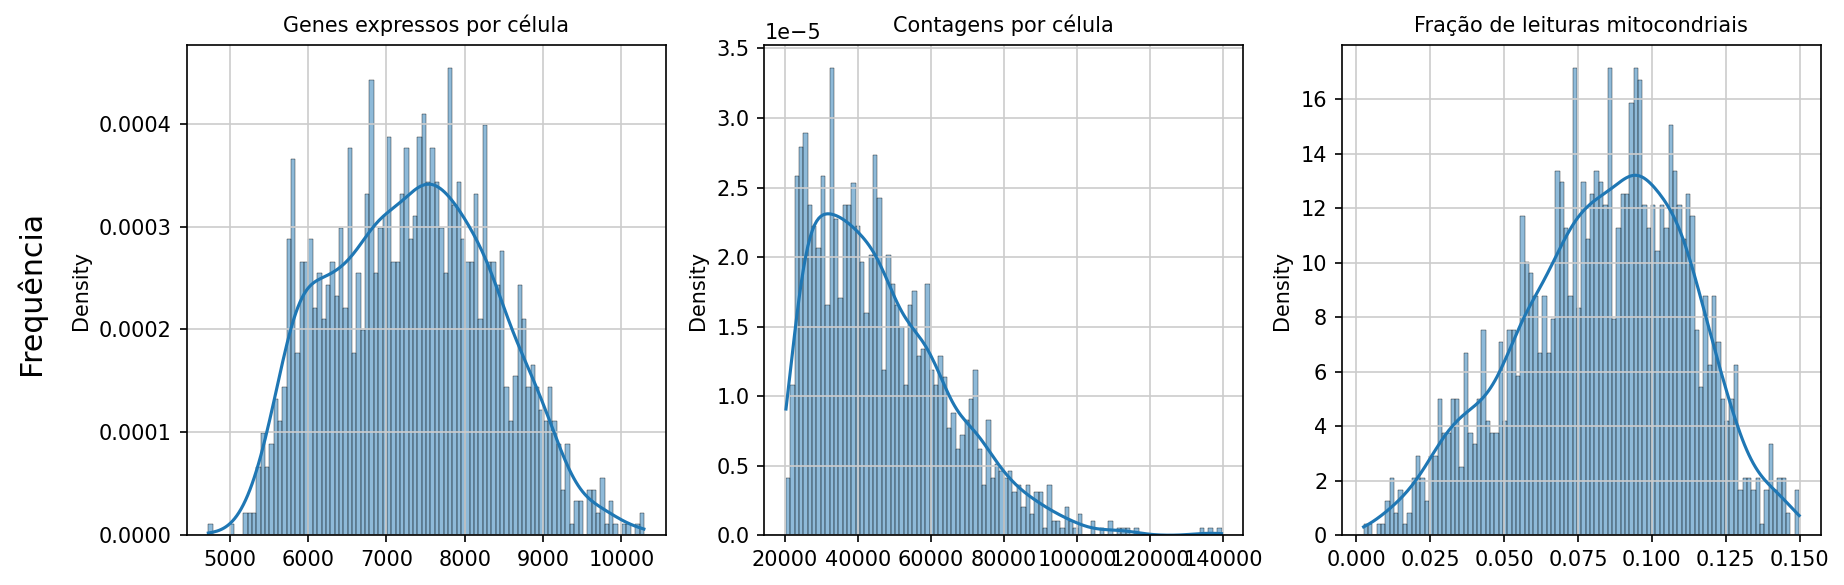

In [17]:
painel_diagnostico(adata, FIG_POS_FILTRO)

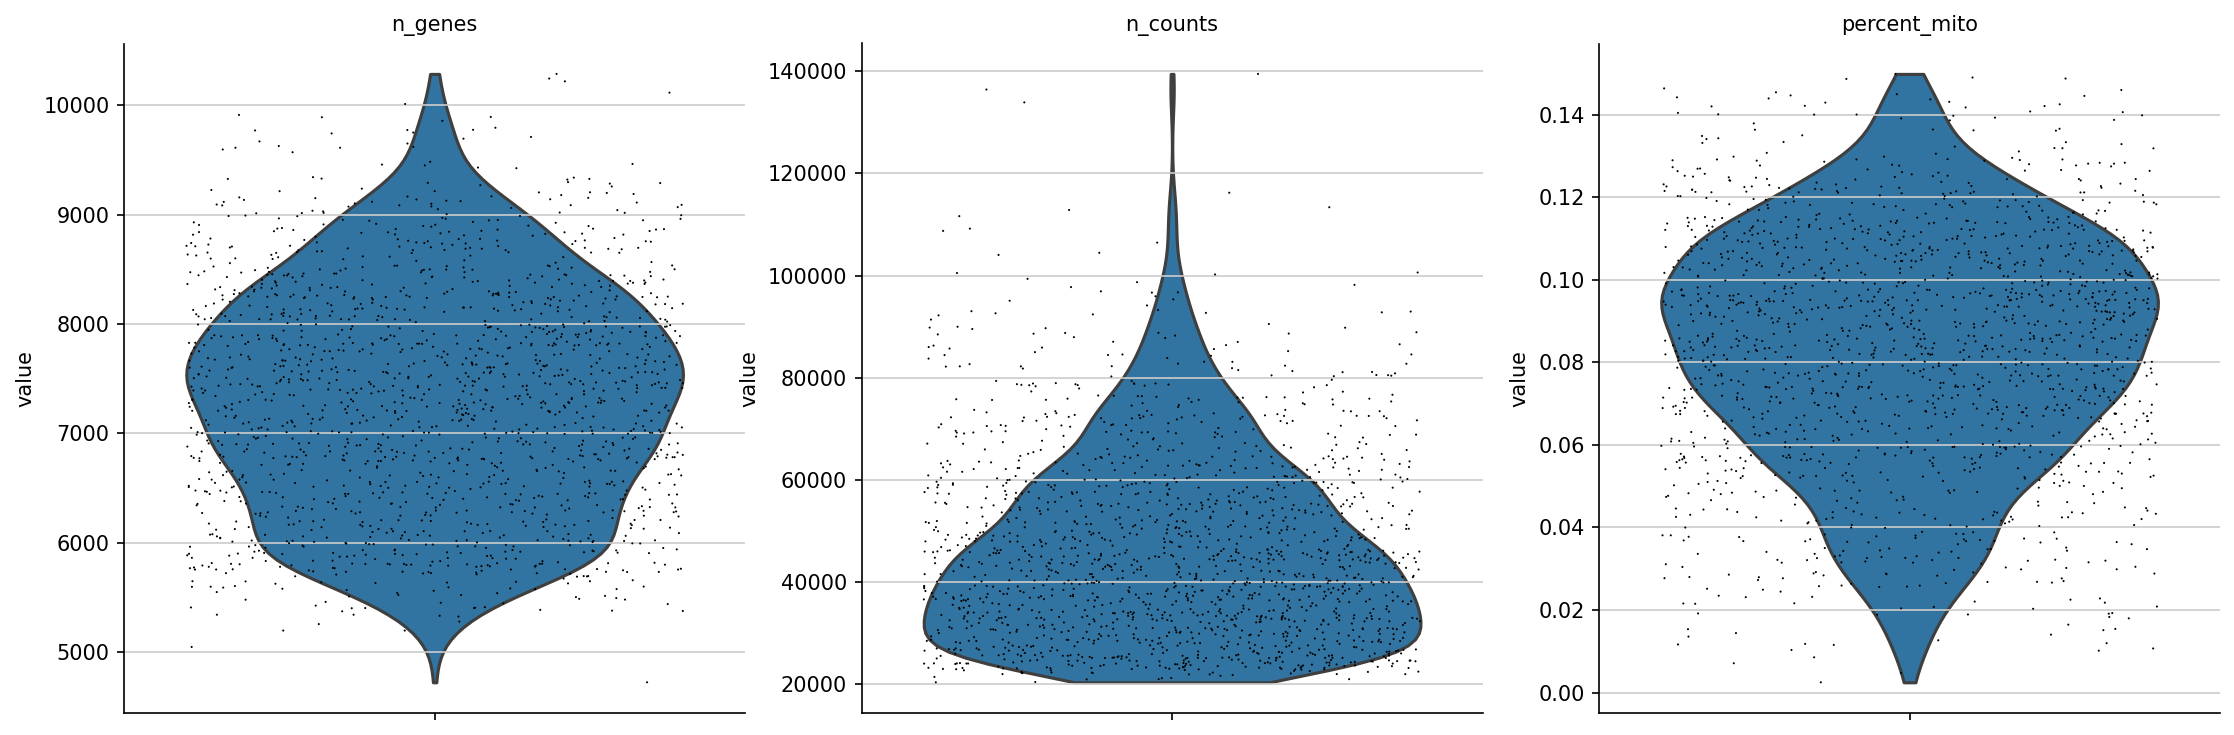

In [18]:
sc.pl.violin(adata, ["n_genes", "n_counts", "percent_mito"], jitter=0.4, multi_panel=True)

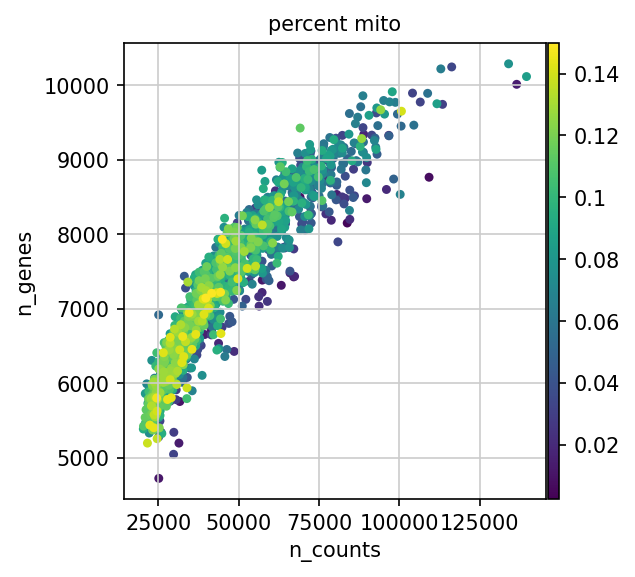

In [19]:
sc.pl.scatter(adata, x="n_counts", y="n_genes", color="percent_mito")

# 6. Arquivos de saída

O objeto do scanpy vai para `data/anndata.h5ad`, com a matriz filtrada e as colunas de qualidade
calculadas aqui, e é o ponto de partida das análises posteriores de agrupamento e visualização.

A matriz filtrada também é gravada em loom, que é o arquivo lido pela etapa de inferência
(`pyscenic grn`) e pelas etapas seguintes da linha de comando. `nGene` e `nUMI` são recalculados
depois da filtragem, então diferem dos do loom da Seção 2.

In [ ]:
adata.write(ANNDATA)

row_attrs = {"Gene": np.array(adata.var_names)}
col_attrs = {
    "CellID": np.array(adata.obs_names),
    "nGene": np.array(np.sum(adata.X.transpose() > 0, axis=0)).flatten(),
    "nUMI": np.array(np.sum(adata.X.transpose(), axis=0)).flatten(),
}

lp.create(str(LOOM_FILTRADO), adata.X.transpose(), row_attrs, col_attrs)

print(f"{ANNDATA}: {adata.n_obs} células x {adata.n_vars} genes")
print(f"{LOOM_FILTRADO}: {adata.n_vars} genes x {adata.n_obs} células")